In [6]:
%pip install -q fastai

Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path

path = Path("../../training_data/patches")

In [3]:
from fastai.vision.all import *

files = get_image_files(path)
files[0]

Path('../../training_data/patches/0/default_mmrsagar_mMRS-BPB_12122023121618_3.png')

In [43]:
# return the name of the parent folder
def label_func(fn: Path):
    return fn.parent.name[-1]


dls = ImageDataLoaders.from_path_func(
    path,
    files,
    label_func,
    item_tfms=Resize(150, method="pad", pad_mode="zeros"),
    bs=32,
)

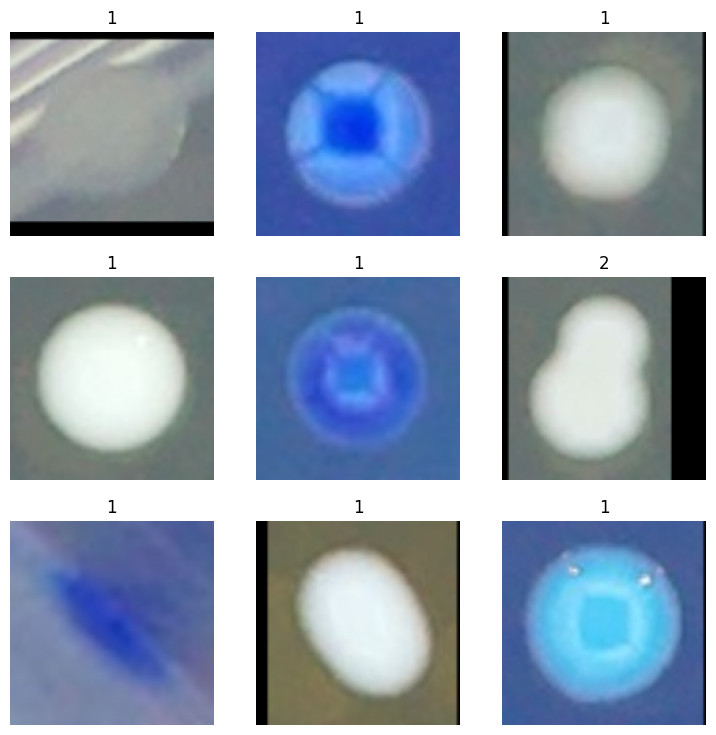

In [44]:
dls.show_batch()

In [45]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(4)

epoch,train_loss,valid_loss,error_rate,time
0,0.772005,0.399819,0.073030,00:25


epoch,train_loss,valid_loss,error_rate,time
0,0.286388,0.308674,0.053507,00:33
1,0.203168,0.206157,0.044830,00:32
2,0.116030,0.182068,0.040492,00:32
3,0.070331,0.159078,0.034707,00:32


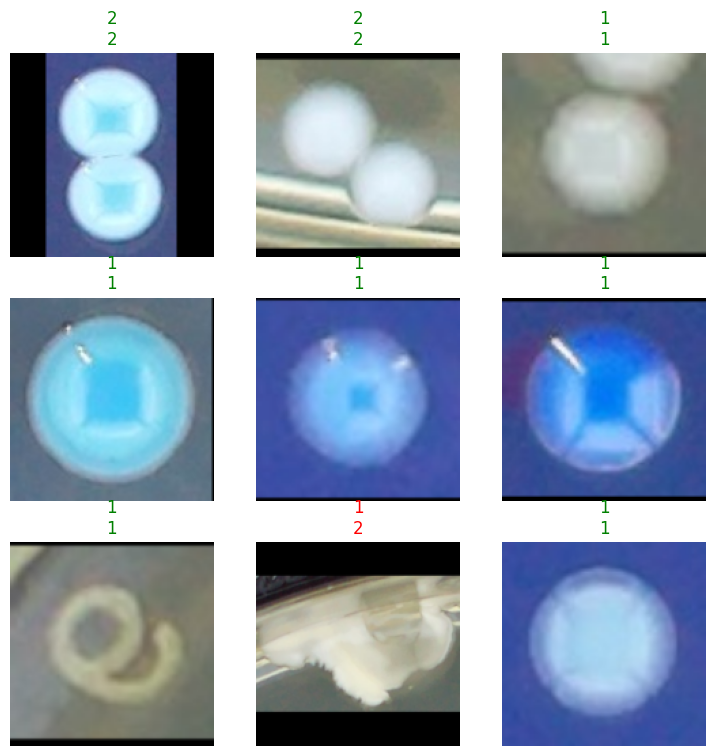

In [55]:
learn.show_results()